# 10 – Can we improve popularity prediction with our existing data?

**Goal (unchanged from notebook 05).** Predict an archived item's **low / medium / high all-time views** (terciles fitted on each training fold) and its **approximate view count** (regression on `log1p(views)`). This estimates *existing archived-item engagement*; it does **not** predict sales or the future success of a book. No new scraping: only `data/popularity_training_clean.csv` (17,727 items) and files already in the repository are used. Notebook 05, its results and all datasets are preserved; everything new is written to `report/ml/popularity_improvements/`.

## Plan
1. **Reproduce 05's baseline** on the same 14,721-item training pool and the same saved grouped CV folds (LogReg and Ridge on the 05 features).
2. **Add features step by step** (each step keeps the previous ones) and keep every result: (1) nonlinear archive age, (2) age × genre, (3) the existing collection flag, (4) consistent author names, (5) author and subject history from *other* books. History features use inner grouped out-of-fold statistics that exclude the book's entire work group; all averages and fallback values come from training rows only.
3. **CatBoost** against the LogReg/Ridge baselines (selected steps only, a two-setting grid).
4. **Ordered classification** (low < medium < high): cumulative binary models and a regression with tuned cut-offs against the plain multinomial classifier, looking closely at the **medium class**.
5. Every comparison is **without description (A)** versus **with description (B)** on the same books and folds. Models and settings are chosen by **training cross-validation only**. The existing holdout has already been examined, so it is reported once at the end as a **historical comparison** and never tuned on.
6. Check whether any existing unused books can give a fresh, work-disjoint final test (no new scraping), and report the limitation if not.

**Never inputs:** views or anything computed from the predicted book's own views, identifiers, run/method/status fields, raw retrieval timestamps (only the archive-age calculation uses them). The collection flag `in_americana` is a *sampling-source indicator*, requested for testing here; it is a shortcut that describes how a book entered our collection, not a property of the book, and is evaluated as a separate step.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import popularity_experiment as pe, popularity_improvements as pi
OUT = pi.OUT; OUT.mkdir(parents=True, exist_ok=True); FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 60, "display.max_rows", 200)
env = pi.environment(); (OUT / "environment_improvements.json").write_text(json.dumps(env, indent=2, default=str), encoding="utf-8")
print({k: env[k] for k in ("python", "scikit-learn", "catboost", "numpy", "pandas", "seed")})

{'python': '3.13.2', 'scikit-learn': '1.6.1', 'catboost': '1.2.10', 'numpy': '2.2.3', 'pandas': '2.2.3', 'seed': 2026}


## 1. Data, saved split and the leakage guard

In [2]:
df = pi.prepare(pe.load_cohort())
manifest = pe.build_split(df, force=False)            # loads 05's saved split; nothing is re-drawn
meta05 = json.loads((pe.OUT / "split_meta.json").read_text(encoding="utf-8")); assert meta05["manifest_sha256"] == pe.sha256_file(pe.OUT / "split_manifest.csv"), "05 split changed"
m = manifest.set_index("identifier").loc[df.identifier]; pm = (m.split == "pool").to_numpy()
pool, hold = df[pm].reset_index(drop=True), df[~pm].reset_index(drop=True); folds = m.cv_fold.to_numpy()[pm].astype(int)
groups = pool.ol_group.to_numpy()
print(f"training pool {len(pool):,} items / {pool.ol_group.nunique():,} works; historical holdout {len(hold):,} items / {hold.ol_group.nunique():,} works; CV folds {np.bincount(folds).tolist()}")
assert not (set(pool.ol_group) & set(hold.ol_group)) and all(pool[folds == k].ol_group.isin(pool[folds != k].ol_group).sum() == 0 for k in range(5))
print("model inputs (before history): publication_year, log_pages, age_years (+ nonlinear), n_creators, n_subjects, title_words, genre flags, juvenile, in_americana (step 3), title+subject words, author names, description words (B)")
print("history inputs (step 5): author mean/log-count and subject mean/log-count of OTHER books; no view-derived value of the predicted book")

training pool 14,721 items / 13,780 works; historical holdout 3,006 items / 2,886 works; CV folds [2946, 2951, 2951, 2930, 2943]
model inputs (before history): publication_year, log_pages, age_years (+ nonlinear), n_creators, n_subjects, title_words, genre flags, juvenile, in_americana (step 3), title+subject words, author names, description words (B)
history inputs (step 5): author mean/log-count and subject mean/log-count of OTHER books; no view-derived value of the predicted book


In [3]:
# Leakage test of the history features. Changing the views of ONE work group must leave that group's OWN history features exactly unchanged
# (while other books' features do move: the test is sensitive). Validation books' own views must not matter either.
tr, te = pool[folds != 0].reset_index(drop=True), pool[folds == 0].reset_index(drop=True)
H0tr, H0te = pi.history_features(tr, te)
worst, moved = 0.0, 0
for g in tr.ol_group.drop_duplicates().sample(10, random_state=2):
    chg = tr.copy(); s = (chg.ol_group == g).to_numpy(); chg.loc[s, "log_views"] += 5.0
    H1, _ = pi.history_features(chg, te); worst = max(worst, float(np.abs(H0tr[s] - H1[s]).max())); moved += int(np.abs(H0tr[~s] - H1[~s]).max() > 1e-9)
print(f"10 work groups, views changed one group at a time: largest change of that group's own history features = {worst}; other books' features moved in {moved}/10 trials (test is sensitive)")
assert worst < 1e-12 and moved == 10
chg_te = te.copy(); chg_te["log_views"] += 5.0; _, H1te = pi.history_features(tr, chg_te)
print("validation books: changing their own views changes their history features by", float(np.abs(H0te - H1te).max())); assert np.abs(H0te - H1te).max() < 1e-12
print("history features pass: a book's own views (and its work group's) never reach its features")

10 work groups, views changed one group at a time: largest change of that group's own history features = 0.0; other books' features moved in 10/10 trials (test is sensitive)
validation books: changing their own views changes their history features by 0.0
history features pass: a book's own views (and its work group's) never reach its features


In [4]:
raw, keys = pool.first_creator.nunique(), pool.author_first.nunique()
print(f"distinct first-creator strings: {raw:,} -> {keys:,} normalised author keys ({(1 - keys / raw):.0%} fewer)")
ex = pool.groupby("author_first").first_creator.agg(lambda s: sorted(set(s))[:4]).loc[lambda s: s.map(len) > 2].head(6)
display(ex.rename("raw spellings that now share one key").to_frame())

distinct first-creator strings: 8,330 -> 6,664 normalised author keys (20% fewer)


,raw spellings that now share one key
author_first,
abnett d,"[Abnett, Dan, Abnett, Dan;Lanning, Andy, Giffen, Keith]"
adams d,"[Adams, Daniel T, author, Adams, Douglas, 1952-2001, Ada..."
aiken j,"[Aiken, Joan, 1924-, Aiken, Joan, 1924-2004, Aiken, Joan..."
alexander h,"[Alexander, Hannah, Alexander, Heather, Alexander, Heath..."
allen c,"[Allen, Christopher (Novelist), author, Allen, Conrad, A..."
anderson j,"[Anderson, Janet, 1946-, Anderson, Jodi Lynn, Anderson, ..."


## 2. Is there a fresh, work-disjoint final test among existing books?
The 05 holdout was already examined, so it cannot be a fresh test. The clean cohort is every collected book with complete inputs (all of them are in the pool or in that holdout). The only books outside it are the 2,544 collected books that failed the description / author checks.

In [5]:
ext, n_excl = pi.load_unused_books()
c = pd.concat({"clean cohort": df.assign(src=df.source_batch), "excluded, work-disjoint": ext.assign(src=ext.source_batch)})
print(f"excluded collected books: {n_excl:,}; of them {len(ext):,} sit in work groups absent from the cohort (the other {n_excl - len(ext)} share a work with a cohort book)")
summ = pd.DataFrame({"books": [len(df), len(ext)], "median views": [df.views.median(), ext.views.median()], "median year": [df.publication_year.median(), ext.publication_year.median()],
                     "share with collection flag": [df.in_americana.mean(), ext.in_americana.mean()], "share with usable description": [1.0, float((ext.description_words >= 25).mean())],
                     "from the older first 5,600 batch": [float((df.source_batch == "first_5600").mean()), float((ext.source_batch == "first_5600").mean())]}, index=["clean cohort", "excluded, work-disjoint"])
display(summ.round(3))
print("Verdict: these books are work-disjoint from every cohort book, but they are a DIFFERENT population (older, collection-flagged, mostly without a usable description), so they cannot serve as a fresh test of the with-description models and only as a limited, shifted check of the metadata-only models (section 8). A fresh with-description test would need new data, which this task does not allow.")

excluded collected books: 2,544; of them 2,374 sit in work groups absent from the cohort (the other 170 share a work with a cohort book)


,books,median views,median year,share with collection flag,share with usable description,"from the older first 5,600 batch"
clean cohort,17727,112.0,2008.0,0.104,1.000,0.159
"excluded, work-disjoint",2374,160.0,1995.0,0.422,0.074,0.960


Verdict: these books are work-disjoint from every cohort book, but they are a DIFFERENT population (older, collection-flagged, mostly without a usable description), so they cannot serve as a fresh test of the with-description models and only as a limited, shifted check of the metadata-only models (section 8). A fresh with-description test would need new data, which this task does not allow.


## 3. Reproducing notebook 05's baseline

In [6]:
cv05 = pd.read_csv(pe.OUT / "cv_summary.csv"); sel05 = pd.read_csv(pe.OUT / "cv_selection.csv")
b05 = cv05[((cv05.algo == "logreg") & (cv05.cfg_id == 2) & (cv05.task == "classification")) | ((cv05.algo == "ridge") & (cv05.cfg_id == 2) & (cv05.task == "regression"))]
print("Notebook 05, CV means (LogReg C=1, Ridge alpha=3):"); display(b05[["variant", "task", "algo", "accuracy", "macro_f1", "r2_log", "median_ae_views", "within_2x"]].round(4))

Notebook 05, CV means (LogReg C=1, Ridge alpha=3):


,variant,task,algo,accuracy,macro_f1,r2_log,median_ae_views,within_2x
6,A,classification,logreg,0.5705,0.5638,NaN,NaN,NaN
21,A,regression,ridge,NaN,NaN,0.4006,62.7567,0.5971
29,B,classification,logreg,0.5791,0.5732,NaN,NaN,NaN
44,B,regression,ridge,NaN,NaN,0.4187,62.7866,0.6031


## 4. Stage 1 – progressive features with the linear baselines (LogReg for classes, Ridge for views)

In [7]:
t0 = time.time()
cv1 = pi.run_cv("ladder", pool, folds, pi.make_specs("ladder", range(6), families={"logreg": [{"C": c} for c in pi.LOGREG_C], "ridge": [{"alpha": a} for a in pi.RIDGE_A]}), n_jobs=5, force=True)
print(f"stage 1 done in {time.time() - t0:.0f} s"); cv1["rows"].round(5).to_csv(OUT / "cv_stage1_all_folds.csv", index=False)
S1 = pi.summarise(cv1["rows"]); S1.round(5).to_csv(OUT / "cv_stage1_summary.csv", index=False)
best_c = pi.best_per(S1, ["variant", "step"], "classification"); best_r = pi.best_per(S1, ["variant", "step"], "regression")
L = best_c.pivot(index="step", columns="variant", values=["accuracy", "macro_f1", "recall_medium"]).join(best_r.pivot(index="step", columns="variant", values=["r2_log", "median_ae_views", "within_2x"]))
L.index = [f"{s}: {pi.STEPS[s]}" for s in L.index]; print("Best of the 3 settings at every step, CV mean over 5 grouped folds"); display(L.round(4))

stage 1 done in 182 s
Best of the 3 settings at every step, CV mean over 5 grouped folds


accuracy         macro_f1         recall_medium          r2_log         median_ae_views          within_2x        
variant                              A       B        A       B             A       B       A       B               A        B         A       B
0: 05 baseline features         0.5705  0.5791   0.5638  0.5732        0.3855  0.3993  0.4006  0.4187         62.7567  62.7866    0.5971  0.6031
1: + nonlinear archive age      0.5704  0.5809   0.5641  0.5754        0.3883  0.4050  0.4093  0.4269         62.4737  62.6434    0.5984  0.6035
2: + age x genre                0.5721  0.5804   0.5659  0.5749        0.3901  0.4055  0.4078  0.4256         62.0717  62.7729    0.5978  0.6023
3: + collection flag            0.5721  0.5791   0.5661  0.5735        0.3929  0.4039  0.4096  0.4275         61.7797  63.0129    0.5974  0.6037
4: + consistent author names    0.5834  0.5895   0.5776  0.5840        0.4046  0.4101  0.4452  0.4589         59.6981  60.6924    0.6152  0.6146
5: + author & subject history   0.6108  0.6156   0.6023  0.6078        0.4033  0.4122  0.4664  0.4822         59.6182  57.6018    0.6307  0.6383

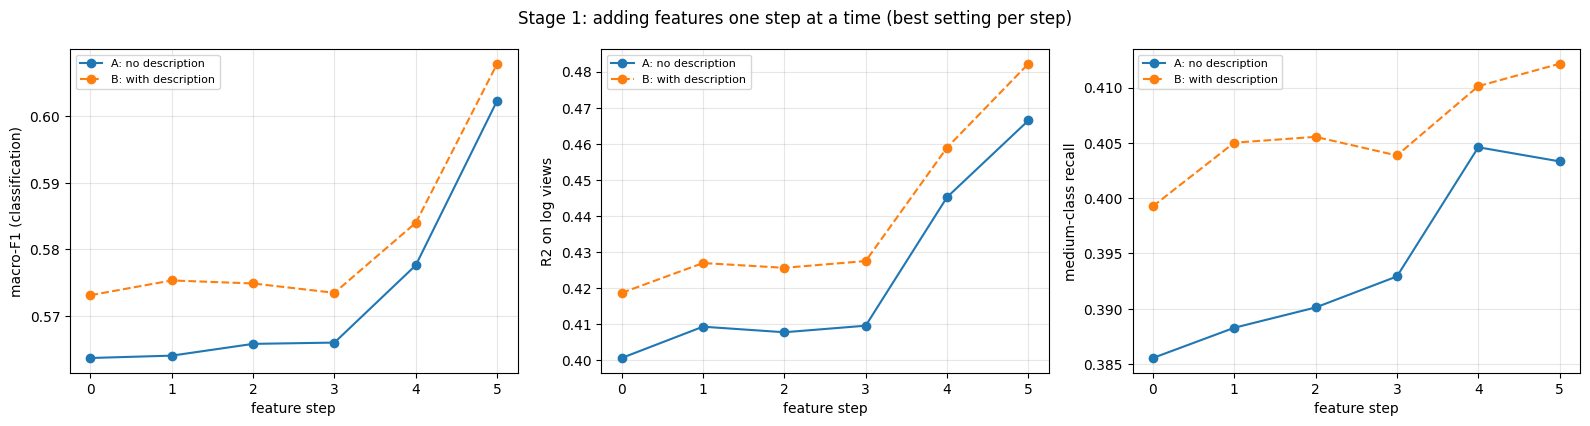

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (met, tb, lab) in zip(ax, [("macro_f1", best_c, "macro-F1 (classification)"), ("r2_log", best_r, "R2 on log views"), ("recall_medium", best_c, "medium-class recall")]):
    for v, st in (("A", "-"), ("B", "--")):
        g = tb[tb.variant == v].sort_values("step"); a.plot(g.step, g[met], st, marker="o", label=f"{v}: {'no description' if v == 'A' else 'with description'}")
    a.set(xlabel="feature step", ylabel=lab, xticks=range(6)); a.grid(alpha=.3); a.legend(fontsize=8)
plt.suptitle("Stage 1: adding features one step at a time (best setting per step)"); plt.tight_layout(); plt.savefig(FIG / "stage1_ladder.png", dpi=130); plt.show()

In [9]:
# what does each step add? paired fold-by-fold differences against the previous step (same fold, best setting of each step)
rows = []
for task, tb, met in (("classification", best_c, "macro_f1"), ("regression", best_r, "r2_log")):
    r = cv1["rows"][cv1["rows"].task == task]
    for v in "AB":
        for step in range(1, 6):
            a = tb[(tb.variant == v) & (tb.step == step - 1)].iloc[0]; b = tb[(tb.variant == v) & (tb.step == step)].iloc[0]
            fa = r[(r.variant == v) & (r.step == step - 1) & (r.family == a.family) & (r.cfg_id == a.cfg_id)].sort_values("fold")[met].to_numpy(); fb = r[(r.variant == v) & (r.step == step) & (r.family == b.family) & (r.cfg_id == b.cfg_id)].sort_values("fold")[met].to_numpy()
            d = fb - fa; rows.append({"task": task, "variant": v, "added at step": f"{step}: {pi.STEPS[step]}", "metric": met, "mean change": d.mean(), "sd of fold changes": d.std(ddof=1), "folds improved": int((d > 0).sum())})
SD = pd.DataFrame(rows); SD.round(4).to_csv(OUT / "stage1_step_effects.csv", index=False); display(SD.round(4))

,task,variant,added at step,metric,mean change,sd of fold changes,folds improved
0,classification,A,1: + nonlinear archive age,macro_f1,0.0004,0.0031,3
1,classification,A,2: + age x genre,macro_f1,0.0018,0.0039,3
2,classification,A,3: + collection flag,macro_f1,0.0002,0.0012,2
3,classification,A,4: + consistent author names,macro_f1,0.0116,0.0018,5
4,classification,A,5: + author & subject history,macro_f1,0.0246,0.0086,5
5,classification,B,1: + nonlinear archive age,macro_f1,0.0022,0.0025,4
6,classification,B,2: + age x genre,macro_f1,-0.0005,0.0052,2
7,classification,B,3: + collection flag,macro_f1,-0.0014,0.0021,1
8,classification,B,4: + consistent author names,macro_f1,0.0105,0.0050,5
9,classification,B,5: + author & subject history,macro_f1,0.0238,0.0043,5


In [10]:
st_cls = {v: int(best_c[best_c.variant == v].sort_values("macro_f1", ascending=False).iloc[0].step) for v in "AB"}; st_reg = {v: int(best_r[best_r.variant == v].sort_values("r2_log", ascending=False).iloc[0].step) for v in "AB"}
print("best step by CV: classification", st_cls, "| regression", st_reg)

best step by CV: classification {'A': 5, 'B': 5} | regression {'A': 5, 'B': 5}


## 5. Stage 2 – CatBoost against the LogReg/Ridge baselines

In [11]:
cb_steps = sorted({0, 5} | set(st_cls.values()) | set(st_reg.values())); print("CatBoost steps:", cb_steps)
specs2 = pi.make_specs("catboost", cb_steps, families={"cb": pi.CB_CFGS}) + pi.make_specs("catboost", [5], families={"cb_cat": [pi.CB_CFGS[1]]})
t0 = time.time(); cv2 = pi.run_cv("catboost", pool, folds, specs2, n_jobs=5, force=True)
print(f"stage 2 done in {time.time() - t0:.0f} s"); cv2["rows"].round(5).to_csv(OUT / "cv_stage2_all_folds.csv", index=False)
S2 = pi.summarise(cv2["rows"]); S2.round(5).to_csv(OUT / "cv_stage2_summary.csv", index=False)
T2 = S2.copy(); T2["setting"] = T2.family + " " + T2.cfg_id.astype(str) + " @step " + T2.step.astype(str)
display(T2[T2.task == "classification"].pivot(index="setting", columns="variant", values=["accuracy", "macro_f1", "recall_medium", "fit_seconds"]).round(3))
display(T2[T2.task == "regression"].pivot(index="setting", columns="variant", values=["r2_log", "median_ae_views", "within_2x", "fit_seconds"]).round(3))

CatBoost steps: [0, 5]


stage 2 done in 875 s


accuracy        macro_f1        recall_medium        fit_seconds         
variant                 A      B        A      B             A      B           A        B
setting                                                                                   
cb 0 @step 0        0.557  0.562    0.547  0.552         0.357  0.356      26.522   46.722
cb 0 @step 5        0.608  0.611    0.600  0.602         0.404  0.406      25.620   45.067
cb 1 @step 0        0.558  0.563    0.550  0.553         0.368  0.360      64.040  121.345
cb 1 @step 5        0.610  0.609    0.603  0.602         0.418  0.409      65.622  121.803
cb_cat 0 @step 5    0.610  0.614    0.604  0.608         0.424  0.426     140.831  207.938

r2_log        median_ae_views         within_2x        fit_seconds         
variant               A      B               A       B         A      B           A        B
setting                                                                                     
cb 0 @step 0      0.328  0.343          66.027  66.099     0.564  0.573      26.522   46.722
cb 0 @step 5      0.463  0.470          57.593  57.050     0.632  0.634      25.620   45.067
cb 1 @step 0      0.335  0.347          65.348  66.001     0.569  0.575      64.040  121.345
cb 1 @step 5      0.465  0.472          56.729  57.470     0.636  0.639      65.622  121.803
cb_cat 0 @step 5  0.468  0.474          58.229  57.704     0.635  0.640     140.831  207.938

## 6. Stage 3 – ordered classification (low < medium < high)
Three ways of respecting the order, compared with the plain multinomial classifier at the same feature step: **cumulative binary models** (P(views above low) and P(views above medium), combined into three class probabilities), a **regression with tuned cut-offs** (cut-offs chosen to maximise macro-F1 on inner out-of-fold training predictions only), and a CatBoost cumulative model.

In [12]:
specs3 = []
for v in "AB":
    for step in sorted({0, st_cls[v]}):
        specs3 += pi.make_specs("ordinal", [step], variants=(v,), families={"cum_lr": [{"C": c} for c in pi.LOGREG_C], "ridge_thr": [{"alpha": a} for a in pi.RIDGE_A], "cb_cum": [pi.CB_CFGS[0]]})
t0 = time.time(); cv3 = pi.run_cv("ordinal", pool, folds, specs3, n_jobs=5, force=True)
print(f"stage 3 done in {time.time() - t0:.0f} s"); cv3["rows"].round(5).to_csv(OUT / "cv_stage3_all_folds.csv", index=False)
S3 = pi.summarise(cv3["rows"]); S3.round(5).to_csv(OUT / "cv_stage3_summary.csv", index=False)
T3 = S3[S3.task == "classification"].copy(); T3["setting"] = T3.family + " " + T3.cfg_id.astype(str) + " @step " + T3.step.astype(str)
display(T3.pivot(index="setting", columns="variant", values=["accuracy", "macro_f1", "recall_low", "recall_medium", "recall_high"]).round(3))
assert all((cv1["true_class"] == cv["true_class"]).all() for cv in (cv2, cv3)), "the same books must have the same classes in every stage"

stage 3 done in 179 s


accuracy        macro_f1        recall_low        recall_medium        recall_high       
variant                    A      B        A      B          A      B             A      B           A      B
setting                                                                                                      
cb_cum 0 @step 0       0.556  0.564    0.552  0.560      0.707  0.713         0.419  0.427       0.540  0.550
cb_cum 0 @step 5       0.614  0.616    0.611  0.613      0.739  0.739         0.459  0.462       0.642  0.644
cum_lr 0 @step 0       0.570  0.584    0.563  0.578      0.726  0.731         0.389  0.409       0.591  0.608
cum_lr 0 @step 5       0.617  0.622    0.613  0.618      0.752  0.757         0.451  0.459       0.645  0.649
cum_lr 1 @step 0       0.579  0.588    0.575  0.586      0.703  0.701         0.428  0.451       0.602  0.609
cum_lr 1 @step 5       0.609  0.617    0.606  0.615      0.724  0.720         0.449  0.467       0.653  0.662
cum_lr 2 @step 0       0.575  0.581    0.573  0.581      0.678  0.662         0.442  0.475       0.602  0.604
cum_lr 2 @step 5       0.596  0.607    0.594  0.607      0.683  0.680         0.455  0.481       0.649  0.659
ridge_thr 0 @step 0    0.573  0.567    0.576  0.570      0.646  0.655         0.516  0.482       0.554  0.564
ridge_thr 0 @step 5    0.592  0.593    0.597  0.597      0.625  0.641         0.534  0.524       0.618  0.613
ridge_thr 1 @step 0    0.577  0.580    0.579  0.582      0.666  0.679         0.495  0.488       0.567  0.572
ridge_thr 1 @step 5    0.608  0.610    0.611  0.614      0.688  0.657         0.524  0.542       0.612  0.632
ridge_thr 2 @step 0    0.563  0.576    0.565  0.577      0.666  0.669         0.470  0.475       0.551  0.581
ridge_thr 2 @step 5    0.610  0.616    0.609  0.614      0.719  0.729         0.479  0.471       0.629  0.646

## 7. Choosing models by cross-validation only

In [13]:
S_all = pd.concat([S1, S2, S3], ignore_index=True)
crit = {"classification": "macro_f1", "regression": "r2_log"}
rows = []
for task in crit:
    s = S_all[(S_all.task == task)].dropna(subset=[crit[task]])
    for v in "AB":
        for fam_name, fams in (("overall best", None),):
            g = s[s.variant == v]; r = g.sort_values(crit[task], ascending=False).iloc[0]; rows.append({"task": task, "variant": v, "role": "overall CV winner", **{k: r[k] for k in ("stage", "step", "family", "cfg_id", "cfg", "accuracy", "macro_f1", "r2_log", "recall_medium")}, "cv_criterion": r[crit[task]]})
        for fam in s.family.unique():
            g = s[(s.variant == v) & (s.family == fam)]; r = g.sort_values(crit[task], ascending=False).iloc[0]; rows.append({"task": task, "variant": v, "role": f"best {fam}", **{k: r[k] for k in ("stage", "step", "family", "cfg_id", "cfg", "accuracy", "macro_f1", "r2_log", "recall_medium")}, "cv_criterion": r[crit[task]]})
SEL = pd.DataFrame(rows); SEL.round(5).to_csv(OUT / "cv_selection.csv", index=False)
(OUT / "cv_selection_written_utc.txt").write_text(pd.Timestamp.utcnow().isoformat())
print("Selection saved BEFORE the historical holdout or the unused books are scored. Criterion: CV macro-F1 (classes) / CV R2 on log views (views).")
display(SEL[SEL.role == "overall CV winner"][["task", "variant", "stage", "step", "family", "cfg", "cv_criterion", "accuracy", "macro_f1", "r2_log", "recall_medium"]].round(4))
base05 = {("classification", v): S1[(S1.family == "logreg") & (S1.step == 0) & (S1.cfg_id == 1) & (S1.variant == v) & (S1.task == "classification")].iloc[0] for v in "AB"}
base05.update({("regression", v): S1[(S1.family == "ridge") & (S1.step == 0) & (S1.cfg_id == 1) & (S1.variant == v) & (S1.task == "regression")].iloc[0] for v in "AB"})
cmp_rows = []
for task in crit:
    for v in "AB":
        w = SEL[(SEL.task == task) & (SEL.variant == v) & (SEL.role == "overall CV winner")].iloc[0]; b = base05[(task, v)]
        cmp_rows.append({"task": task, "variant": v, "05 baseline (CV)": b[crit[task]], "CV winner (CV)": w.cv_criterion, "gain": w.cv_criterion - b[crit[task]], "winner": f"{w.family} {w.cfg_id} @ step {int(w.step)}"})
print("Winner against the 05 baseline, cross-validation:"); display(pd.DataFrame(cmp_rows).round(4))

Selection saved BEFORE the historical holdout or the unused books are scored. Criterion: CV macro-F1 (classes) / CV R2 on log views (views).


,task,variant,stage,step,family,cfg,cv_criterion,accuracy,macro_f1,r2_log,recall_medium
0,classification,A,ordinal,5,cum_lr,"{""C"": 0.3}",0.6126,0.6169,0.6126,NaN,0.4511
7,classification,B,ordinal,5,cum_lr,"{""C"": 0.3}",0.6183,0.6223,0.6183,NaN,0.4585
14,regression,A,catboost,5,cb_cat,"{""depth"": 6, ""iterations"": 500, ""learning_rate"": 0.05, ""...",0.4683,NaN,NaN,0.4683,NaN
19,regression,B,ladder,5,ridge,"{""alpha"": 10.0}",0.4822,NaN,NaN,0.4822,NaN


Winner against the 05 baseline, cross-validation:


,task,variant,05 baseline (CV),CV winner (CV),gain,winner
0,classification,A,0.5638,0.6126,0.0488,cum_lr 0 @ step 5
1,classification,B,0.5732,0.6183,0.0451,cum_lr 0 @ step 5
2,regression,A,0.4006,0.4683,0.0677,cb_cat 0 @ step 5
3,regression,B,0.4187,0.4822,0.0635,ridge 2 @ step 5


In [14]:
# the per-class picture, pooled out-of-fold predictions of the same books (classes from each fold's own training cut-offs)
cvs = {"ladder": cv1, "catboost": cv2, "ordinal": cv3}; true_c = cv1["true_class"]; views = pool.views.to_numpy()
def oof(stage, v, step, fam, cid, kind): return cvs[stage]["oof"][(stage, v, step, fam, cid, kind)]
show = {}
for v in "AB":
    show[f"{v}: 05 baseline LogReg"] = oof("ladder", v, 0, "logreg", 1, "cls")
    w = SEL[(SEL.task == "classification") & (SEL.variant == v) & (SEL.role == "overall CV winner")].iloc[0]; show[f"{v}: CV winner {w.family} @step {int(w.step)}"] = oof(w.stage, v, int(w.step), w.family, int(w.cfg_id), "cls")
    for fam, nm in (("cum_lr", "cumulative LogReg"), ("ridge_thr", "Ridge + tuned cut-offs"), ("cb_cum", "CatBoost cumulative")):
        r = SEL[(SEL.task == "classification") & (SEL.variant == v) & (SEL.role == f"best {fam}")]
        if len(r): r = r.iloc[0]; show[f"{v}: {nm} @step {int(r.step)}"] = oof(r.stage, v, int(r.step), fam, int(r.cfg_id), "cls")
rows = []
for k, p in show.items():
    cm = pi.pooled_cls(true_c, p); rec = cm.diagonal() / cm.sum(1); rows.append({"model": k, "accuracy": cm.diagonal().sum() / cm.sum(), **{f"recall {c}": r for c, r in zip(pi.CLASS_NAMES, rec)}, **pi.medium_errors(cm)})
PC = pd.DataFrame(rows); PC.round(4).to_csv(OUT / "oof_per_class_and_medium_errors.csv", index=False); display(PC.round(3))

,model,accuracy,recall low,recall medium,recall high,medium_recall,medium_to_low,medium_to_high,severe_errors_low_high
0,A: 05 baseline LogReg,0.570,0.703,0.386,0.621,0.386,0.326,0.288,0.076
1,A: CV winner cum_lr @step 5,0.617,0.752,0.451,0.645,0.451,0.302,0.247,0.051
2,A: cumulative LogReg @step 5,0.617,0.752,0.451,0.645,0.451,0.302,0.247,0.051
3,A: Ridge + tuned cut-offs @step 5,0.608,0.688,0.524,0.612,0.524,0.268,0.208,0.038
4,A: CatBoost cumulative @step 5,0.614,0.739,0.459,0.642,0.459,0.298,0.243,0.052
5,B: 05 baseline LogReg,0.579,0.710,0.400,0.626,0.400,0.315,0.285,0.069
6,B: CV winner cum_lr @step 5,0.622,0.757,0.459,0.649,0.459,0.298,0.243,0.047
7,B: cumulative LogReg @step 5,0.622,0.757,0.459,0.649,0.459,0.298,0.243,0.047
8,B: Ridge + tuned cut-offs @step 5,0.610,0.657,0.542,0.632,0.542,0.243,0.215,0.033
9,B: CatBoost cumulative @step 5,0.616,0.739,0.463,0.644,0.463,0.291,0.247,0.048


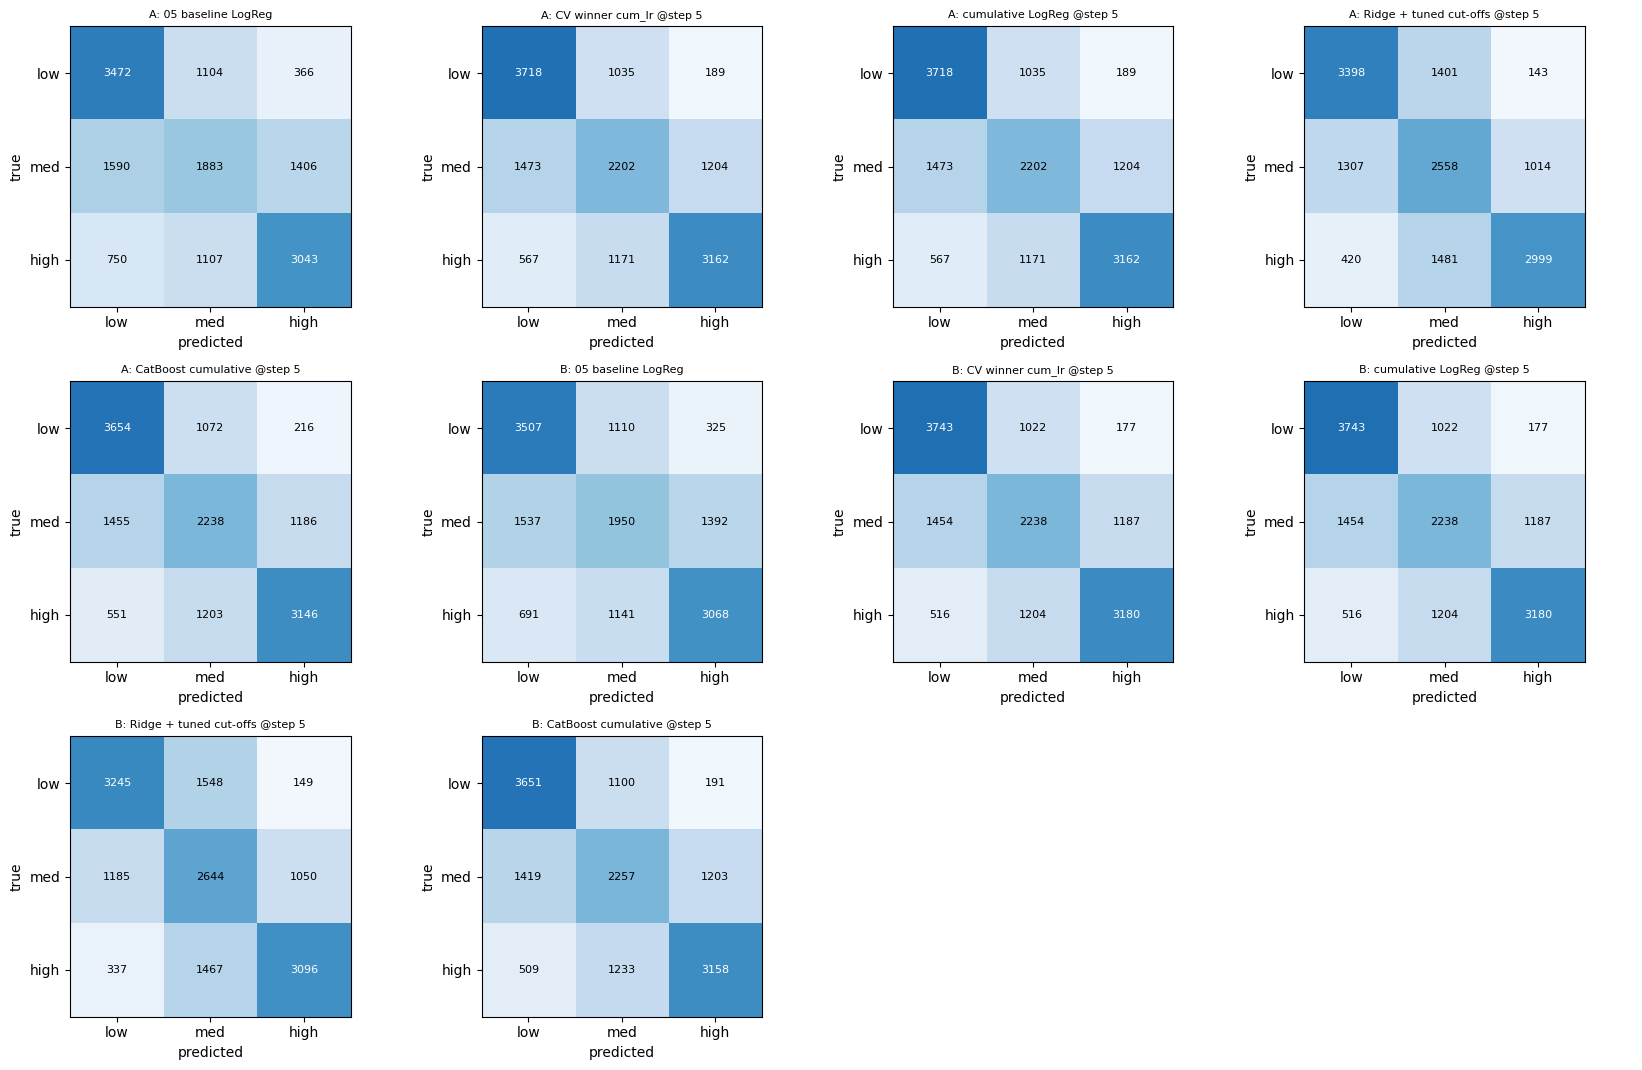

In [15]:
keys = list(show); n = len(keys); cols = 4; rws = int(np.ceil(n / cols)); fig, ax = plt.subplots(rws, cols, figsize=(4.2 * cols, 3.6 * rws)); ax = np.atleast_2d(ax)
for a in ax.ravel(): a.axis("off")
for a, k in zip(ax.ravel(), keys):
    a.axis("on"); cm = pi.pooled_cls(true_c, show[k]); a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): a.text(j, i, str(cm[i, j]), ha="center", va="center", color="black" if cm[i, j] / cm[i].sum() < .6 else "white", fontsize=8)
    a.set(xticks=range(3), yticks=range(3), xticklabels=["low", "med", "high"], yticklabels=["low", "med", "high"], title=k, xlabel="predicted", ylabel="true"); a.title.set_fontsize(8)
plt.tight_layout(); plt.savefig(FIG / "oof_confusion_matrices.png", dpi=130); plt.show()

In [16]:
# is the gain over the 05 baseline reliable? group bootstrap on the pooled out-of-fold predictions of the SAME books (CV only)
rows = []
for v in "AB":
    wc = SEL[(SEL.task == "classification") & (SEL.variant == v) & (SEL.role == "overall CV winner")].iloc[0]; wr = SEL[(SEL.task == "regression") & (SEL.variant == v) & (SEL.role == "overall CV winner")].iloc[0]
    rows.append({"variant": v, "task": "classification", "comparison": f"winner ({wc.family} @step {int(wc.step)}) minus 05 baseline", **pi.boot_diff(groups, true_c, views, oof("ladder", v, 0, "logreg", 1, "cls"), oof(wc.stage, v, int(wc.step), wc.family, int(wc.cfg_id), "cls"), "cls")})
    rows.append({"variant": v, "task": "regression", "comparison": f"winner ({wr.family} @step {int(wr.step)}) minus 05 baseline", **pi.boot_diff(groups, true_c, views, oof("ladder", v, 0, "ridge", 1, "reg"), oof(wr.stage, v, int(wr.step), wr.family, int(wr.cfg_id), "reg"), "reg")})
BD = pd.DataFrame(rows); BD.round(4).to_csv(OUT / "cv_bootstrap_vs_baseline.csv", index=False)
print("Difference (winner minus 05 baseline), 95% interval over resampled work groups, pooled out-of-fold predictions")
display(BD[["variant", "task", "comparison", "accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95", "r2_log_mean", "r2_log_lo95", "r2_log_hi95", "median_ae_views_mean", "median_ae_views_lo95", "median_ae_views_hi95"]].round(3))
# description effect inside the CV winner family
rows = []
for task, kind, met in (("classification", "cls", "macro_f1"), ("regression", "reg", "r2_log")):
    wa = SEL[(SEL.task == task) & (SEL.variant == "A") & (SEL.role == "overall CV winner")].iloc[0]; wb = SEL[(SEL.task == task) & (SEL.variant == "B") & (SEL.role == "overall CV winner")].iloc[0]
    pa, pb = oof(wa.stage, "A", int(wa.step), wa.family, int(wa.cfg_id), kind), oof(wb.stage, "B", int(wb.step), wb.family, int(wb.cfg_id), kind)
    rows.append({"task": task, "comparison": f"B winner ({wb.family} @step {int(wb.step)}) minus A winner ({wa.family} @step {int(wa.step)})", **pi.boot_diff(groups, true_c, views, pa, pb, kind)})
display(pd.DataFrame(rows)[["task", "comparison", "accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95", "r2_log_mean", "r2_log_lo95", "r2_log_hi95"]].round(3))

Difference (winner minus 05 baseline), 95% interval over resampled work groups, pooled out-of-fold predictions


,variant,task,comparison,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95,r2_log_mean,r2_log_lo95,r2_log_hi95,median_ae_views_mean,median_ae_views_lo95,median_ae_views_hi95
0,A,classification,winner (cum_lr @step 5) minus 05 baseline,0.047,0.040,0.054,0.049,0.042,0.057,NaN,NaN,NaN,NaN,NaN,NaN
1,A,regression,winner (cb_cat @step 5) minus 05 baseline,NaN,NaN,NaN,NaN,NaN,NaN,0.068,0.057,0.077,-4.392,-6.035,-2.741
2,B,classification,winner (cum_lr @step 5) minus 05 baseline,0.043,0.037,0.050,0.045,0.038,0.052,NaN,NaN,NaN,NaN,NaN,NaN
3,B,regression,winner (ridge @step 5) minus 05 baseline,NaN,NaN,NaN,NaN,NaN,NaN,0.063,0.055,0.072,-5.268,-6.586,-3.821


,task,comparison,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95,r2_log_mean,r2_log_lo95,r2_log_hi95
0,classification,B winner (cum_lr @step 5) minus A winner (cum_lr @step 5),0.005,0.002,0.009,0.006,0.002,0.009,NaN,NaN,NaN
1,regression,B winner (ridge @step 5) minus A winner (cb_cat @step 5),NaN,NaN,NaN,NaN,NaN,NaN,0.014,0.008,0.02


## 8. Historical holdout and the unused books (reported once, never tuned on)
The 05 holdout (3,006 items, new works) was **already examined** while notebook 05 was built, so it is a *historical comparison*, not a fresh test. The settings below were fixed by the cross-validation above before it is scored. The unused books are a work-disjoint but shifted, metadata-only check (section 2).

In [17]:
assert pd.Timestamp((OUT / "cv_selection_written_utc.txt").read_text()) < pd.Timestamp.utcnow()
def spec(role_row, label, step=None):
    return dict(stage="final", label=label, step=int(role_row.step if step is None else step), variant=role_row.variant, family=role_row.family, cfg_id=int(role_row.cfg_id), cfg=json.loads(role_row.cfg))
final = []
for v in "AB":
    final += [dict(stage="final", label="05 baseline", step=0, variant=v, family="logreg", cfg_id=1, cfg={"C": 1.0}), dict(stage="final", label="05 baseline", step=0, variant=v, family="ridge", cfg_id=1, cfg={"alpha": 3.0})]
    for task in crit:
        for role in ("overall CV winner", "best cb", "best cum_lr", "best ridge_thr"):
            r = SEL[(SEL.task == task) & (SEL.variant == v) & (SEL.role == role)]
            if len(r): final.append(spec(r.iloc[0], role))
seen, uniq = set(), []
for s in final:
    k = (s["label"], s["variant"], s["step"], s["family"], s["cfg_id"])
    if k not in seen: seen.add(k); uniq.append(s)
t0 = time.time(); H_res, H_pred, H_true, H_cuts = pi.fit_score(pool, hold, uniq)
print(f"historical holdout scored in {time.time() - t0:.0f} s; pool tercile cut-offs {np.round(H_cuts, 1)}; holdout class counts {np.bincount(H_true).tolist()}")
H_res.round(5).to_csv(OUT / "holdout_historical_results.csv", index=False)
h05 = pd.read_csv(pe.OUT / "holdout_results.csv"); h05 = h05[(h05.algo.isin(["logreg", "ridge"]))]
print("Notebook 05, historical holdout (for reference):"); display(h05[["variant", "task", "algo", "accuracy", "macro_f1", "r2_log", "median_ae_views", "within_2x"]].round(4))
c = H_res[H_res.task == "classification"]; display(c[["label", "variant", "step", "family", "accuracy", "macro_f1", "recall_low", "recall_medium", "recall_high"]].round(4))
r = H_res[H_res.task == "regression"]; display(r[["label", "variant", "step", "family", "r2_log", "mae_views", "median_ae_views", "within_2x"]].round(4))

historical holdout scored in 391 s; pool tercile cut-offs [ 70. 205.]; holdout class counts [1058, 1017, 931]
Notebook 05, historical holdout (for reference):


,variant,task,algo,accuracy,macro_f1,r2_log,median_ae_views,within_2x
2,A,classification,logreg,0.5735,0.5653,NaN,NaN,NaN
8,A,regression,ridge,NaN,NaN,0.3997,58.5070,0.6074
11,B,classification,logreg,0.5935,0.5853,NaN,NaN,NaN
17,B,regression,ridge,NaN,NaN,0.4186,59.2932,0.6158


,label,variant,step,family,accuracy,macro_f1,recall_low,recall_medium,recall_high
0,05 baseline,A,0,logreg,0.5735,0.5653,0.7287,0.3805,0.6079
2,overall CV winner,A,5,cum_lr,0.6154,0.6106,0.7609,0.4395,0.6423
3,best cb,A,5,cb,0.6221,0.6161,0.7684,0.4366,0.6584
5,best cum_lr,A,5,cum_lr,0.6154,0.6106,0.7609,0.4395,0.6423
6,best ridge_thr,A,5,ridge_thr,0.6131,0.6149,0.7155,0.5329,0.5843
8,overall CV winner,A,5,cb_cat,0.6194,0.6147,0.7552,0.4464,0.6541
10,05 baseline,B,0,logreg,0.5935,0.5852,0.7457,0.3972,0.6348
12,overall CV winner,B,5,cum_lr,0.6284,0.6243,0.7703,0.4661,0.6445
13,best cb,B,5,cb,0.6208,0.6128,0.7788,0.4189,0.6617
15,best cum_lr,B,5,cum_lr,0.6284,0.6243,0.7703,0.4661,0.6445


,label,variant,step,family,r2_log,mae_views,median_ae_views,within_2x
1,05 baseline,A,0,ridge,0.3997,257.3961,58.5070,0.6075
4,best cb,A,5,cb,0.4779,245.1259,52.5107,0.6607
7,best ridge_thr,A,5,ridge_thr,0.4663,251.1483,53.2032,0.6457
9,overall CV winner,A,5,cb_cat,0.4802,245.0307,51.4652,0.6557
11,05 baseline,B,0,ridge,0.4186,255.3663,59.2932,0.6158
14,best cb,B,5,cb,0.4848,245.9241,51.3806,0.6647
17,best ridge_thr,B,5,ridge_thr,0.4820,250.5443,54.5291,0.6487
18,overall CV winner,B,5,ridge,0.4880,248.6108,51.3785,0.6517
20,best cb,B,5,cb,0.4865,246.6534,51.5803,0.6574
22,best ridge_thr,B,5,ridge_thr,0.4880,248.6108,51.3785,0.6517


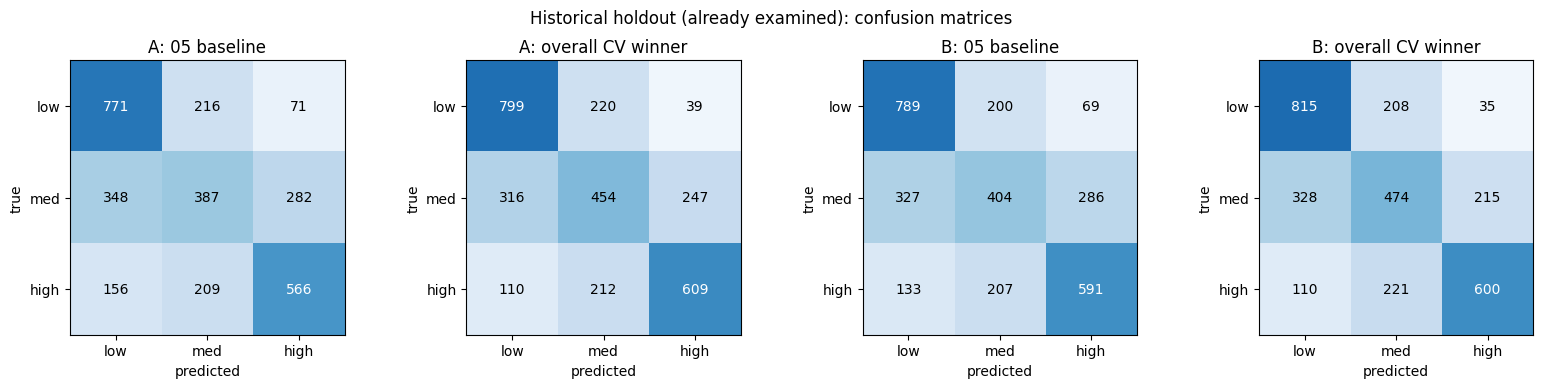

In [18]:
sel_c = [(k, p) for k, p in H_pred.items() if k[2] == "cls" and k[0] in ("05 baseline", "overall CV winner")]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, ((lab, v, _), p) in zip(ax, sel_c):
    cm = pi.pooled_cls(H_true, p); a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): a.text(j, i, str(cm[i, j]), ha="center", va="center", color="black" if cm[i, j] / cm[i].sum() < .6 else "white")
    a.set(xticks=range(3), yticks=range(3), xticklabels=["low", "med", "high"], yticklabels=["low", "med", "high"], title=f"{v}: {lab}", xlabel="predicted", ylabel="true")
plt.suptitle("Historical holdout (already examined): confusion matrices"); plt.tight_layout(); plt.savefig(FIG / "holdout_confusion_matrices.png", dpi=130); plt.show()

In [5]:
# the unused, work-disjoint books: metadata-only (A) models only
specsA = [s for s in uniq if s["variant"] == "A"]
t0 = time.time(); X_res, X_pred, X_true, _ = pi.fit_score(pool, ext, specsA)
print(f"unused books scored in {time.time() - t0:.0f} s | {len(ext):,} books; class counts with the pool's cut-offs {np.bincount(X_true, minlength=3).tolist()}")
X_res.round(5).to_csv(OUT / "unused_books_check_results.csv", index=False)
display(X_res[X_res.task == "classification"][["label", "family", "step", "accuracy", "macro_f1", "recall_low", "recall_medium", "recall_high"]].round(4))
display(X_res[X_res.task == "regression"][["label", "family", "step", "r2_log", "mae_views", "median_ae_views", "within_2x"]].round(4))

unused books scored in 206 s | 2,374 books; class counts with the pool's cut-offs [531, 858, 985]


,label,family,step,accuracy,macro_f1,recall_low,recall_medium,recall_high
0,05 baseline,logreg,0,0.5990,0.5899,0.5876,0.4068,0.7726
2,overall CV winner,cum_lr,5,0.6318,0.6258,0.6328,0.4674,0.7746
3,best cb,cb,5,0.6272,0.6252,0.6271,0.4953,0.7421
5,best cum_lr,cum_lr,5,0.6318,0.6258,0.6328,0.4674,0.7746
6,best ridge_thr,ridge_thr,5,0.6196,0.6163,0.5913,0.5186,0.7228
8,overall CV winner,cb_cat,5,0.6302,0.6282,0.6328,0.4965,0.7452


,label,family,step,r2_log,mae_views,median_ae_views,within_2x
1,05 baseline,ridge,0,0.4088,268.1838,93.4962,0.5859
4,best cb,cb,5,0.4486,261.9588,86.9631,0.6179
7,best ridge_thr,ridge_thr,5,0.4282,290.9030,90.8588,0.6066
9,overall CV winner,cb_cat,5,0.4505,259.2727,87.7798,0.6104


## 9. Findings

All numbers are from this executed notebook; nothing new was scraped. "Baseline" means notebook 05's LogReg / Ridge on 05's features, reproduced exactly here (CV macro-F1 0.564 / 0.573, R² 0.401 / 0.419 for without / with description). The target is *existing archived-item engagement*, not sales or future success.

## Short answer
**Yes, a little, and mostly because of authors.** Cross-validation on the training pool improves by about **4–5 points of accuracy and macro-F1** for the low/medium/high classes and by about **0.06 R²** (typically 4–5 fewer views of median error) for the view estimate. This is far from 85 %: the best three-class accuracy is about 62 %. No particular accuracy is promised.

## What helped, step by step (cross-validation, best of three settings per step; "folds" = how many of the 5 grouped folds improved)
| Step added | Effect on macro-F1 (A / B) | Effect on R² (A / B) | Verdict |
|---|---|---|---|
| 1 nonlinear archive age | +0.000 / +0.002 | **+0.009 / +0.008** (5/5 folds) | small help for views |
| 2 age × genre | +0.002 / −0.001 | −0.002 / −0.001 | **no help** (kept in the table) |
| 3 collection flag | +0.000 / −0.001 | +0.002 / +0.002 | **no real help** (and a sampling shortcut) |
| 4 consistent author names | **+0.012 / +0.011** (5/5) | **+0.036 / +0.031** (5/5) | **clear help** |
| 5 author + subject history of other books | **+0.025 / +0.024** (5/5) | **+0.021 / +0.023** (5/5) | **clear help** |

Together: macro-F1 0.564 → 0.602 and R² 0.401 → 0.466 (A, multinomial LogReg / Ridge); 0.573 → 0.608 and 0.419 → 0.482 (B). History features passed the leakage test (changing a book's own views or its work group's views changes none of its own features).

## CatBoost: no clear advantage
At the best feature step CatBoost scored macro-F1 0.603 / 0.602 (A / B) against 0.602 / 0.608 for LogReg, and R² 0.465 / 0.472 against 0.466 / 0.482 for Ridge. Letting CatBoost use the author as a native category gave 0.468 (A), only 0.002 above Ridge: noise. It is also slower to fit (about 35–65 s against under 1–6 s). CatBoost is not worth its complexity here.

## Ordered classification: helps the medium class, with a trade-off
Cumulative binary models (P(above low), P(above medium)) beat the plain multinomial classifier at the same features: macro-F1 0.613 / 0.618 against 0.602 / 0.608 (A / B). They also raise medium-class recall from 0.386 / 0.400 (baseline) to 0.451 / 0.459 and cut the severe low↔high mistakes from 7.6 % / 6.9 % to 5.1 % / 4.7 %. A regression with tuned cut-offs raises medium recall most (0.524 / 0.542) and reduces severe mistakes to 3.8 % / 3.3 %, but it pays for that with lower recall for the low class (0.688 / 0.657) and lower accuracy (0.608 / 0.610). Medium is still the hardest class: even the best model gets under half of the true medium books right.

## Chosen by cross-validation (selection saved before any holdout was scored)
* Classification: cumulative LogReg at step 5, both variants: CV macro-F1 **0.613 (A) / 0.618 (B)** against the baseline 0.564 / 0.573: gain **+4.9 points (95 % interval +4.2 to +5.7) / +4.5 (+3.8 to +5.2)** on the pooled out-of-fold predictions of the same books; accuracy 0.617 / 0.622 against 0.570 / 0.579.
* Views: Ridge at step 5 (B) and CatBoost with a native author category (A, only 0.002 ahead of Ridge): R² **0.468 / 0.482** against 0.401 / 0.419 (+0.068 / +0.063, intervals +0.057 to +0.077 and +0.055 to +0.072); median absolute error 4.4 and 5.3 views lower (intervals exclude 0).

## Do descriptions still help?
Slightly. With the best models on the same books and folds, B minus A is +0.006 macro-F1 (+0.002 to +0.009), +0.005 accuracy (+0.002 to +0.009) and +0.014 R² (+0.008 to +0.020). That is small compared with the gains from author information.

## Historical holdout (already examined in notebook 05, never tuned on)
| 3,006 items | Baseline | Chosen models |
|---|---|---|
| Accuracy / macro-F1, A | 57.4 % / 0.565 | 61.5 % / 0.611 |
| Accuracy / macro-F1, B | 59.4 % / 0.585 | 62.8 % / 0.624 |
| Medium-class recall (A / B) | 0.38 / 0.40 | 0.44 / 0.47 |
| R² on log views (A / B) | 0.400 / 0.419 | 0.480 / 0.488 |
| Median absolute error, views (A / B) | 58.5 / 59.3 | 51.5 / 51.4 |
| Within 2× of the actual count (A / B) | 60.7 % / 61.6 % | 65.6 % / 65.2 % |

The direction and size agree with cross-validation, but because this holdout had already been inspected it is a historical comparison, not fresh evidence.

## Is there a fresh final test? No (limitation)
Every item in the clean cohort is either in the training pool or in the already-examined holdout. The only unused collected books are 2,374 items in work groups absent from the cohort, but they are a different population (96 % from the older batch, median year 1995, 42 % collection-flagged, only 7 % with a usable description). They can only test the **metadata-only** models, with a distribution shift: there the baseline scored 59.9 % accuracy / macro-F1 0.590 and R² 0.409; the chosen models scored 63.2 % / 0.626 and R² 0.451 (median error 93.5 → 87.8 views). That is encouraging, but it is neither a with-description test nor a like-for-like one. A genuinely fresh test of the with-description models would need new data.

## Limits and honest caveats
* **Most of the gain comes from authors and subjects that recur across works.** Consistent author names and author/subject history help because the same authors and series appear in different works (always in different work groups, never the same work). The gain should shrink for an author with no other books in the data; this notebook did not measure that separately.
* Choosing the best of many candidates by the same cross-validation makes the winning CV score slightly optimistic.
* The collection flag is a sampling-source indicator, not a book property. It did not help, so nothing is lost by leaving it out.
* Views describe engagement with an archived copy, not sales or future success, and archive age is an input.
* Failed or neutral ideas (age × genre, the collection flag, CatBoost, the tuned-cut-off trade-off) are kept in the tables above.

## 10. Reproduce
```bash
pip install -r requirements-analysis.txt            # includes catboost
cd notebooks && jupyter nbconvert --to notebook --execute --inplace 10_popularity_improvements.ipynb   # about 30-40 minutes on 16 CPU threads
```
Code: `notebooks/popularity_improvements.py` (reuses `popularity_experiment.py`, which is unchanged). Seeds: split/CV 2026 (05's saved split), history inner folds 2026, CatBoost 2026. Results and figures: `report/ml/popularity_improvements/`.

## 11. Try it: one training book and one unseen book
Run **Setup** once, then run either example. Each prediction **fits the already-chosen models once** on the 14,721 saved training books (about 15 s; no cross-validation, no holdout scoring, no change to any file). The models are the ones selected by cross-validation in section 7: the step-5 features (author-name, author/subject-history and the other added features), a **cumulative LogReg** for low / medium / high and a **Ridge** for the view estimate, each **without** and **with** the description. The observed views are shown *beside* the prediction and are never an input.

Edit `BOOK` to try another book (required: `title`, `publication_year`, `pages`, `archive_years`; optional: `description`, `author`, `subjects` separated by ` | `, `genre`, `juvenile`). `archive_years` is how long the item has been on archive.org, not the book's age. `collection_flag` is a sampling-source indicator of our collection; leave it 0 for a book that is not in it. Author and subject history only helps if the author/subjects occur in our training data; for an unknown author the model has nothing to go on. Leave `description` empty to see only the without-description row.

Both books were drawn by a **seeded random draw** (seed 2032), not hand-picked, and the results are shown whatever they are. The estimates describe *existing archived-item engagement*, not sales or future success. Classes: low ≤ 70 views, medium 71-205, high > 205 (the training pool's tercile cut-offs).

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display
sys.path.insert(0, str(Path.cwd()))
import popularity_experiment as pe, popularity_improvements as pi
_df = pi.prepare(pe.load_cohort()); _m = pe.build_split(_df, force=False).set_index("identifier").loc[_df.identifier]
pool_demo = _df[(_m.split == "pool").to_numpy()].reset_index(drop=True)
SEL_demo = pd.read_csv(pi.OUT / "cv_selection.csv")

def show_popularity(BOOK, OBSERVED_VIEWS=None):
    t0 = time.time(); res, cuts = pi.demo_predict(pool_demo, [BOOK], SEL_demo); res = res.drop(columns="book")
    if not (BOOK.get("description") or "").strip():
        res = res[res.Inputs == "Without description"]; print("No description entered: only the without-description model is shown.")
    if OBSERVED_VIEWS is not None:
        obs_cls = "low" if OBSERVED_VIEWS <= cuts[0] else ("high" if OBSERVED_VIEWS > cuts[1] else "medium")
        res["Observed views"] = OBSERVED_VIEWS; res["Observed popularity"] = obs_cls; res["Class matches?"] = res["Predicted popularity"] == obs_cls
        res["Absolute error (views)"] = (res["Estimated views"] - OBSERVED_VIEWS).abs(); res["Within 2x?"] = (res["Estimated views"] + 1).div(OBSERVED_VIEWS + 1).between(0.5, 2)
    print("Book:", BOOK["title"], "|", BOOK.get("author", ""), f"| ({time.time() - t0:.0f} s)"); display(res.reset_index(drop=True))

### 11.1 Training book (in the training pool) — *Burning paradise*
Observed all-time views: **153** (medium). Source: <https://archive.org/details/burningparadise0000wils>. This book **was used to fit the models**, and the author/subject statistics the model uses were computed from training books that include this book's own work group, so this is a *familiar-example check*, not evidence that the model generalises.

In [2]:
BOOK = {'title': 'Burning paradise',
 'description': '"Cassie Iverson, eighteen years old, lives in the United States in the year 2014--but it\'s not our United States and '
                "it's not our 2014. Cassie's world has been at peace since the Great Armistice of 1914. But Cassie knows the world isn't "
                'what it seems. Her parents were part of a group who gradually discovered the awful truth: that for decades--back to the '
                'dawn of radio communications--human progress has been interfered with, made more peaceful and benign, by an '
                "extraterrestrial entity. Cassie's parents were killed for this knowledge, along with most of the other members of their "
                'group. Cassie and her younger brother Thomas now live with her aunt Nerissa, who shares these dangerous secrets. For '
                'seven years they have attempted to lead unexceptional lives in order to escape detection. The tactic has worked. Until '
                'now. Because the killers are back. And they\'re not human"-- "A Tom Doherty Associates book."',
 'author': 'Wilson, Robert Charles, 1953- author',
 'publication_year': 2013,
 'pages': 330,
 'genre': 'science_fiction',
 'subjects': 'Science fiction | Extraterrestrial beings -- Fiction | Alternate world -- Fiction',
 'archive_years': 7.16,
 'juvenile': False,
 'collection_flag': 0}
OBSERVED_VIEWS = 153   # observed on archive.org; shown beside the prediction, never an input
show_popularity(BOOK, OBSERVED_VIEWS)

Book: Burning paradise | Wilson, Robert Charles, 1953- author | (9 s)


,Inputs,Predicted popularity,Low (%),Medium (%),High (%),Estimated views,Observed views,Observed popularity,Class matches?,Absolute error (views),Within 2x?
0,Without description,low,56.0,37.5,6.4,88,153,medium,False,65,True
1,With description,low,54.1,40.5,5.4,72,153,medium,False,81,False


### 11.2 Unseen book (work never used for fitting) — *The novice*
Observed all-time views: **3,041** (high). Source: <https://archive.org/details/novice0000math>. This book comes from the 05 historical holdout: its work group is not in the training pool. It was not scraped again; its saved details are used. One example is an illustration only: the full held-out results are in sections 7-8. Very popular books are the model's known weak point (the view estimate shrinks toward typical values), so a miss on a high-view book is expected.

In [3]:
BOOK = {'title': 'The novice',
 'description': 'When blacksmith apprentice Fletcher discovers that he has the ability to summon demons from another world, he travels to '
                'Adept Military Academy. There the gifted are trained in the art of summoning. Fletcher is put through grueling training '
                "as a battlemage to fight in the Hominum Empire's war against orcs. He must tread carefully while training alongside "
                'children of powerful nobles. The power hungry, those seeking alliances, and the fear of betrayal surround him. Fletcher '
                'finds himself caught in the middle of powerful forces, with only his demon Ignatius for help. As the pieces on the board '
                'maneuver for supremacy, Fletcher must decide where his loyalties lie. The fate of an empire is in his hands Young Adult '
                '890 Reading Counts! 5.7 Accelerated Reader 6.5',
 'author': 'Matharu, Taran, author',
 'publication_year': 2015,
 'pages': 390,
 'genre': 'fantasy',
 'subjects': 'Blacksmiths -- Apprentices -- Juvenile fiction | Demonology -- Juvenile fiction | Boarding schools -- Juvenile fiction | '
             'Imaginary wars and battles -- Juvenile fiction | Apprentices -- Fiction | Schools -- Fiction | Demonology -- Fiction | '
             'Imaginary wars and battles -- Fiction | Fantasy | YOUNG ADULT FICTION -- Action & Adventure | YOUNG ADULT FICTION -- Fantasy '
             '| Boarding schools | Demonology | Imaginary wars and battles',
 'archive_years': 6.37,
 'juvenile': True,
 'collection_flag': 0}
OBSERVED_VIEWS = 3041   # observed on archive.org; shown beside the prediction, never an input
show_popularity(BOOK, OBSERVED_VIEWS)

Book: The novice | Matharu, Taran, author | (9 s)


,Inputs,Predicted popularity,Low (%),Medium (%),High (%),Estimated views,Observed views,Observed popularity,Class matches?,Absolute error (views),Within 2x?
0,Without description,medium,27.8,40.7,31.6,140,3041,high,False,2901,False
1,With description,medium,25.7,42.5,31.8,168,3041,high,False,2873,False
